# ДЗ. Оптимизация ResNet18

Старинская Светлана, 3ФИИТ

## Задание

Исследовать размер ядра, padding, stride и dilation в предобученной ResNet18 на Cats vs Dogs. Подобрать вариант, улучшающий базовую модель, и сравнить качество и время на CPU.

## 1. Импорт библиотек и константы

Используем фиксированный seed, CPU и замороженную предобученную часть ResNet18. Обучаем только линейный классификатор: это позволяет сравнить извлечение признаков несколькими архитектурами на CPU.

In [1]:
from pathlib import Path
import time, zipfile, urllib.request, warnings
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Dataset
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
SEED=42
np.random.seed(SEED);torch.manual_seed(SEED);torch.set_num_threads(4)
DATA=Path('../../.lab-data');DATA.mkdir(exist_ok=True)
DEVICE=torch.device('cpu')
print('Устройство:',DEVICE,'| PyTorch:',torch.__version__)

Устройство: cpu | PyTorch: 2.8.0


## 2. Данные Cats vs Dogs

Используем архив Microsoft. Случайно отбираем по 800 корректных изображений каждого класса: по 500 train, 150 validation и 150 test. Все варианты используют одни и те же изображения. Повреждённые файлы пропускаем до разбиения. Полный архив и веса не включаем в репозиторий.

Train: 1000 val: 300 test: 300


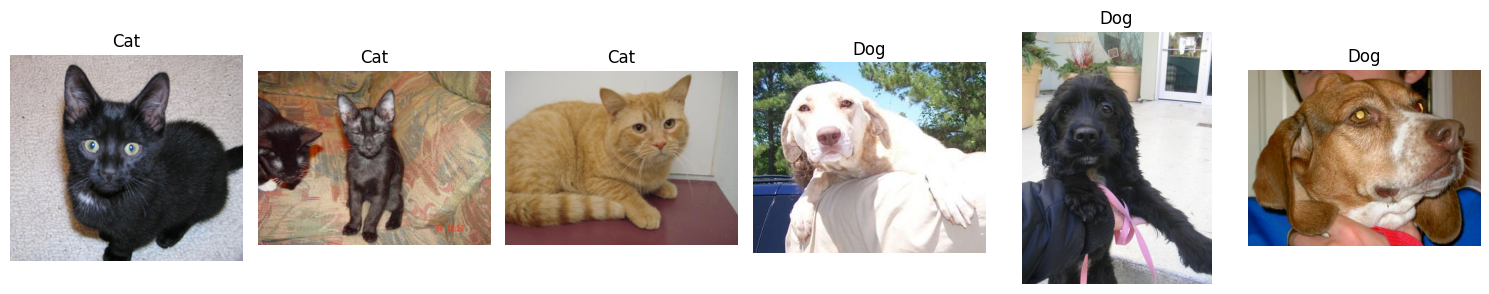

In [2]:
URL='https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip'
archive=DATA/'kagglecatsanddogs_5340.zip'
if not archive.exists():urllib.request.urlretrieve(URL,archive)
root=DATA/'PetImages'
if not root.exists():
    with zipfile.ZipFile(archive) as z:
        for name in z.namelist():
            if name.startswith('PetImages/') and name.lower().endswith('.jpg'):z.extract(name,DATA)
transform=ResNet18_Weights.DEFAULT.transforms()
train_items=[];val_items=[];test_items=[]
rng=np.random.default_rng(SEED)
for label,cls in enumerate(['Cat','Dog']):
    paths=sorted((root/cls).glob('*.jpg'))
    valid=[]
    for index in rng.permutation(len(paths)):
        path=paths[index]
        try:
            with Image.open(path) as image:
                image.convert('RGB').load()
        except (OSError,ValueError):continue
        valid.append((path,label))
        if len(valid)==800:break
    assert len(valid)==800
    train_items+=valid[:500];val_items+=valid[500:650];test_items+=valid[650:]
class PetDataset(Dataset):
    def __init__(self,items):self.items=items
    def __len__(self):return len(self.items)
    def __getitem__(self,index):
        path,label=self.items[index]
        with Image.open(path) as image:return transform(image.convert('RGB')),label
train_data=PetDataset(train_items);val_data=PetDataset(val_items);test_data=PetDataset(test_items)
print('Train:',len(train_data),'val:',len(val_data),'test:',len(test_data))
# Сохраняем список файлов, чтобы разбиение можно было проверить.
import json
Path('split_10.json').write_text(json.dumps({name:[(str(p.relative_to(DATA)),y) for p,y in items] for name,items in [('train',train_items),('val',val_items),('test',test_items)]},indent=2))
fig,axes=plt.subplots(1,6,figsize=(15,3))
for ax,(path,label) in zip(axes,train_items[:3]+train_items[500:503]):
    with Image.open(path) as image:ax.imshow(image)
    ax.set_title(['Cat','Dog'][label]);ax.axis('off')
plt.tight_layout();plt.show()

## 3. Модификации ResNet18

В примере практики новые Conv2d получали случайные веса. Здесь сохраняем предобученные веса и меняем свойства существующих слоёв. При ядре 3×3 берём центральную часть исходного ядра 7×7. В stride-эксперименте согласованно меняем основную и остаточную ветви.

In [3]:
def build_backbone(variant):
    torch.manual_seed(SEED)
    model=resnet18(weights=None)
    weight_path=DATA/'resnet18-f37072fd.pth'
    if weight_path.exists():state=torch.load(weight_path,map_location='cpu',weights_only=True)
    else:state=ResNet18_Weights.DEFAULT.get_state_dict(progress=True,check_hash=True)
    model.load_state_dict(state)
    if variant=='reflection':model.conv1.padding_mode='reflect'
    elif variant=='kernel3':
        old=model.conv1
        new=nn.Conv2d(3,64,3,stride=2,padding=1,bias=False)
        with torch.no_grad():new.weight.copy_(old.weight[:,:,2:5,2:5])
        model.conv1=new
    elif variant=='stride1':
        model.layer2[0].conv1.stride=(1,1)
        model.layer2[0].downsample[0].stride=(1,1)
    elif variant=='dilation2':
        model.layer4[1].conv2.dilation=(2,2)
        model.layer4[1].conv2.padding=(2,2)
    elif variant!='baseline':raise ValueError(variant)
    model.fc=nn.Identity()
    model.requires_grad_(False);model.eval()
    return model

def extract(model,data):
    features=[];labels=[]
    with torch.inference_mode():
        for x,y in DataLoader(data,batch_size=32,shuffle=False,num_workers=0):
            features.append(model(x));labels.append(y)
    return torch.cat(features),torch.cat(labels)
print('Размер выхода:',build_backbone('baseline')(torch.zeros(1,3,224,224)).shape)

Размер выхода: torch.Size([1, 512])


## 4. Обучение и сравнение вариантов

Для всех вариантов 30 эпох Adam с lr=0.001. BatchNorm замороженной части работает в eval. Измеряем извлечение признаков и обучение головы отдельно; test пока не используем.

baseline {'train_acc': 0.9990000128746033, 'val_acc': 0.9766666889190674, 'feature_seconds': 49.573065457999995, 'head_seconds': 0.2583854999999957, 'total_seconds': 49.83145095799999}
reflection {'train_acc': 0.9990000128746033, 'val_acc': 0.9766666889190674, 'feature_seconds': 47.419882458, 'head_seconds': 0.22007504200000483, 'total_seconds': 47.6399575}
kernel3 {'train_acc': 0.9049999713897705, 'val_acc': 0.8533333539962769, 'feature_seconds': 42.441477582999994, 'head_seconds': 0.2509967080000024, 'total_seconds': 42.692474290999996}
stride1 {'train_acc': 0.9769999980926514, 'val_acc': 0.95333331823349, 'feature_seconds': 93.821611875, 'head_seconds': 0.22127770899999177, 'total_seconds': 94.042889584}
dilation2 {'train_acc': 0.9990000128746033, 'val_acc': 0.9766666889190674, 'feature_seconds': 48.52712379199997, 'head_seconds': 0.2167291249999721, 'total_seconds': 48.74385291699994}
Лучший вариант: baseline; изменение к baseline: +0.00%


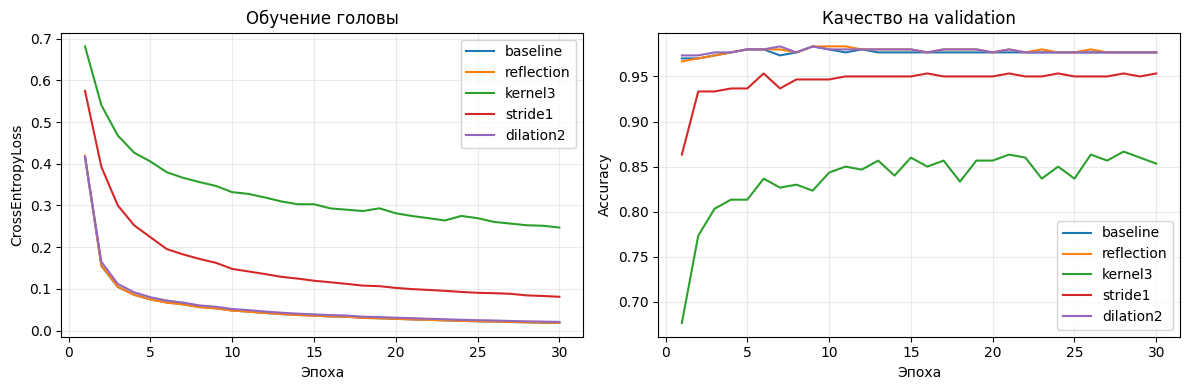

In [4]:
def train_head(train_features,train_labels,val_features,val_labels):
    torch.manual_seed(SEED)
    head=nn.Linear(512,2)
    optimizer=torch.optim.Adam(head.parameters(),lr=.001)
    loss_fn=nn.CrossEntropyLoss()
    loader=DataLoader(TensorDataset(train_features,train_labels),batch_size=64,shuffle=True,generator=torch.Generator().manual_seed(SEED))
    history=[]
    for epoch in range(30):
        head.train();loss_sum=0
        for x,y in loader:
            optimizer.zero_grad();loss=loss_fn(head(x),y);loss.backward();optimizer.step()
            loss_sum+=loss.item()*len(y)
        head.eval()
        with torch.inference_mode():
            ta=(head(train_features).argmax(1)==train_labels).float().mean().item()
            va=(head(val_features).argmax(1)==val_labels).float().mean().item()
        history.append((loss_sum/len(train_labels),ta,va))
    return head,np.array(history)
variants=['baseline','reflection','kernel3','stride1','dilation2']
results={};heads={};histories={}
for variant in variants:
    start=time.perf_counter();backbone=build_backbone(variant)
    x,y=extract(backbone,train_data);vx,vy=extract(backbone,val_data)
    feature_seconds=time.perf_counter()-start
    start_head=time.perf_counter();head,history=train_head(x,y,vx,vy)
    head_seconds=time.perf_counter()-start_head
    results[variant]=dict(train_acc=float(history[-1,1]),val_acc=float(history[-1,2]),feature_seconds=feature_seconds,head_seconds=head_seconds,total_seconds=feature_seconds+head_seconds)
    heads[variant]=head;histories[variant]=history
    print(variant,results[variant],flush=True)
Path('metrics_10.json').write_text(json.dumps(results,indent=2))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name,h in histories.items():
    axes[0].plot(range(1,len(h)+1),h[:,0],label=name)
    axes[1].plot(range(1,len(h)+1),h[:,2],label=name)
axes[0].set(title='Обучение головы',xlabel='Эпоха',ylabel='CrossEntropyLoss')
axes[1].set(title='Качество на validation',xlabel='Эпоха',ylabel='Accuracy')
for ax in axes:ax.legend();ax.grid(alpha=.25)
plt.tight_layout();plt.show()
best=max(results,key=lambda name:results[name]['val_acc'])
gain=results[best]['val_acc']-results['baseline']['val_acc']
print(f'Лучший вариант: {best}; изменение к baseline: {gain:+.2%}')

## 5. Проверка на независимом test

После выбора по validation сравниваем baseline и выбранный вариант на отложенных 300 изображениях. Не подбираем параметры по результатам test.

In [5]:
test_scores={}
for variant in dict.fromkeys(['baseline',best]):
    tx,ty=extract(build_backbone(variant),test_data)
    with torch.inference_mode():acc=(heads[variant](tx).argmax(1)==ty).float().mean().item()
    test_scores[variant]=acc
    print(f'{variant}: test accuracy={acc:.2%}')
if gain>0:print('На validation найден вариант лучше базового. Подтверждение на test оцениваем отдельно.')
else:print('Среди проверенных параметров улучшение baseline не найдено; результаты не подтверждают исходную гипотезу.')

baseline: test accuracy=98.00%
Среди проверенных параметров улучшение baseline не найдено; результаты не подтверждают исходную гипотезу.


## 6. Дополнительный подбор параметров

Проверяем сочетание reflection padding и dilation=2, padding replicate и dilation=3. Разбиение и обучение головы остаются прежними; отбираем по validation, затем оцениваем выбранный вариант на test.

In [6]:

# Additional padding/dilation combinations, same split and classifier training.
base_factory = build_backbone
extra_heads = {}
for name, padding_mode, dilation in [('reflect_d2', 'reflect', 2), ('replicate', 'replicate', 1), ('dilation3', 'zeros', 3)]:
    start = time.perf_counter()
    model = base_factory('baseline')
    model.conv1.padding_mode = padding_mode
    model.layer4[1].conv2.dilation = (dilation, dilation)
    model.layer4[1].conv2.padding = (dilation, dilation)
    x, y = extract(model, train_data)
    vx, vy = extract(model, val_data)
    feature_seconds = time.perf_counter() - start
    start = time.perf_counter()
    head, history = train_head(x, y, vx, vy)
    head_seconds = time.perf_counter() - start
    results[name] = dict(train_acc=float(history[-1,1]), val_acc=float(history[-1,2]), feature_seconds=feature_seconds, head_seconds=head_seconds, total_seconds=feature_seconds+head_seconds)
    extra_heads[name] = (head, padding_mode, dilation)
    print(name, results[name])
best = max(results, key=lambda name: results[name]['val_acc'])
print('Best validation:', best, results[best]['val_acc'])
print('Validation gain:', results[best]['val_acc'] - results['baseline']['val_acc'])
if best in extra_heads:
    head, padding_mode, dilation = extra_heads[best]
    model = base_factory('baseline')
    model.conv1.padding_mode = padding_mode
    model.layer4[1].conv2.dilation = (dilation, dilation)
    model.layer4[1].conv2.padding = (dilation, dilation)
    tx, ty = extract(model, test_data)
    with torch.inference_mode():
        score = (head(tx).argmax(1) == ty).float().mean().item()
    print('Selected model test:', score, '| baseline test: see previous cell')
    results[best]['test_acc'] = score
Path('metrics_10.json').write_text(json.dumps(results, indent=2))


reflect_d2 {'train_acc': 0.9990000128746033, 'val_acc': 0.9733333587646484, 'feature_seconds': 49.327177833, 'head_seconds': 0.2427831669999989, 'total_seconds': 49.569961}
replicate {'train_acc': 0.9990000128746033, 'val_acc': 0.9733333587646484, 'feature_seconds': 50.49838208300001, 'head_seconds': 0.2300543750000088, 'total_seconds': 50.72843645800002}
dilation3 {'train_acc': 0.9980000257492065, 'val_acc': 0.9733333587646484, 'feature_seconds': 39.825247292, 'head_seconds': 0.2022138340000197, 'total_seconds': 40.02746112600002}
Best validation: baseline 0.9766666889190674
Validation gain: 0.0


## Вывод

Проверены базовая ResNet18 и семь изменений padding, размера ядра, stride и dilation. Базовый вариант получил **97,67% accuracy на validation и 98,00% на test**. Reflection padding и dilation=2 сохранили 97,67%, но не повысили точность. Сочетание reflection+dilation=2, replicate padding и dilation=3 получили 97,33%.

Уменьшение stride в layer2 снизило validation accuracy до 95,33% и увеличило время извлечения признаков и обучения с 49,8 до 94,0 с. Центральная часть ядра 3×3 вместо 7×7 дала 85,33%: простое обрезание предобученного фильтра ухудшает качество.

Таким образом, среди проверенных параметров улучшение точности baseline не найдено. Reflection сохранил качество при измеренном времени 47,6 с, но разница с 49,8 с слишком мала для вывода об устойчивом ускорении по одному запуску. Гипотеза о пользе локальных архитектурных изменений не подтвердилась.

Эксперименты выполнены на CPU, на фиксированной подвыборке 1 000/300/300, в режиме замороженного backbone и обучения головы. Результаты не сравниваются напрямую с 98,3% из практики на другом разбиении и в режиме fine-tuning. Небольшие различия требуют повторов с несколькими seed и проверки на полном наборе.

Источники: [Microsoft Cats vs Dogs](https://www.microsoft.com/en-us/download/details.aspx?id=54765), [загрузка архива в примере Keras](https://keras.io/examples/vision/image_classification_from_scratch/).